In [31]:
import os
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline  # <-- Adicione esta linha
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier

In [32]:
warnings.filterwarnings('ignore')

In [33]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

DB_PATH = './datawarehouse/datawarehouse.db'

In [34]:
def carregar_dados_dw(db_path=DB_PATH):
    print("[1/6] Conectando ao Data Warehouse SQLite e carregando tabelas...")
    
    if not os.path.exists(db_path):
        raise FileNotFoundError(f"Banco de dados não encontrado no caminho: {db_path}")

    conn = sqlite3.connect(db_path)

    query_vendas = """
    SELECT 
        fv.id_venda,
        fv.id_cliente,
        fv.id_vendedor,
        fv.id_produto,
        fv.id_tempo,
        fv.quantidade,
        fv.preco_unitario,
        fv.desconto,
        fv.valor_total,
        fv.canal,
        fv.forma_pagamento,
        fv.hora_venda,
        dp.categoria,
        dp.produto,
        dp.estoque_atual,
        dt.data AS data_venda
    FROM fato_vendas fv
    LEFT JOIN dim_produto dp ON fv.id_produto = dp.id_produto
    LEFT JOIN dim_tempo dt ON fv.id_tempo = dt.id_tempo
    """
    
    df_vendas = pd.read_sql_query(query_vendas, conn)
    df_clientes = pd.read_sql_query("SELECT * FROM dim_cliente", conn)
    df_produtos = pd.read_sql_query("SELECT * FROM dim_produto", conn)
    df_promocoes = pd.read_sql_query("SELECT * FROM dim_promocao", conn)
    df_vendedores = pd.read_sql_query("SELECT * FROM dim_vendedor", conn)

    conn.close()

    df_clientes = df_clientes.drop_duplicates(subset=['id_cliente']).copy()
    
    df_vendas['valor_total'] = pd.to_numeric(df_vendas['valor_total'], errors='coerce').fillna(0.0)
    df_vendas['desconto'] = pd.to_numeric(df_vendas['desconto'], errors='coerce').fillna(0.0)
    df_vendas['quantidade'] = pd.to_numeric(df_vendas['quantidade'], errors='coerce').fillna(1)
    df_vendas['data_venda'] = pd.to_datetime(df_vendas['data_venda'], errors='coerce')
    df_clientes['data_cadastro'] = pd.to_datetime(df_clientes['data_cadastro'], errors='coerce')

    return df_clientes, df_vendas, df_produtos, df_promocoes, df_vendedores

In [35]:
def criar_atributos(df_clientes, df_vendas, df_promocoes, df_produtos):
    print("[2/6] Realizando Engenharia de Atributos Avançada...")

    data_referencia = pd.to_datetime('2026-11-08')
    vendas_validas = df_vendas.dropna(subset=['id_cliente']).copy()
    vendas_validas['id_cliente'] = vendas_validas['id_cliente'].astype(int)

    vendas_validas['teve_desconto'] = (vendas_validas['desconto'] > 0).astype(int)
    preco_medio_geral = vendas_validas['valor_total'].mean()

    agg_vendas = vendas_validas.groupby('id_cliente').agg(
        total_compras=('id_venda', 'nunique'),
        total_gasto=('valor_total', 'sum'),
        ticket_medio=('valor_total', 'mean'),
        desconto_medio=('desconto', 'mean'),
        proporcao_promocao=('teve_desconto', 'mean'),
        qtd_itens_total=('quantidade', 'sum'),
        ultima_compra=('data_venda', 'max'),
        forma_pagto_preferida=('forma_pagamento', lambda x: x.mode()[0] if not x.empty else 'Não informado')
    ).reset_index()

    agg_vendas['dias_desde_ultima_compra'] = (
        data_referencia - pd.to_datetime(agg_vendas['ultima_compra'], errors='coerce')
    ).dt.days.fillna(999)
    agg_vendas.drop(columns=['ultima_compra'], inplace=True)

    agg_vendas['razao_ticket_preco_medio'] = agg_vendas['ticket_medio'] / (preco_medio_geral + 1e-5)

    cat_counts = vendas_validas.groupby(['id_cliente', 'categoria']).size().unstack(fill_value=0)
    cat_proporcoes = cat_counts.div(cat_counts.sum(axis=1), axis=0)
    cat_proporcoes.columns = [f'pct_compras_{col.lower().replace(" ", "_")}' for col in cat_proporcoes.columns]
    cat_proporcoes = cat_proporcoes.reset_index()

    categoria_preferida = cat_counts.idxmax(axis=1).reset_index()
    categoria_preferida.columns = ['id_cliente', 'categoria_alvo']

    vendas_crediario = vendas_validas[vendas_validas['forma_pagamento'] == 'Crediário']
    agg_crediario = vendas_crediario.groupby('id_cliente').agg(
        total_compras_crediario=('id_venda', 'count'),
        valor_total_crediario=('valor_total', 'sum')
    ).reset_index()

    df_ml = df_clientes.merge(agg_vendas, on='id_cliente', how='left')
    df_ml = df_ml.merge(cat_proporcoes, on='id_cliente', how='left')
    df_ml = df_ml.merge(agg_crediario, on='id_cliente', how='left')
    df_ml = df_ml.merge(categoria_preferida, on='id_cliente', how='left')

    df_ml['total_compras'] = df_ml['total_compras'].fillna(0)
    df_ml['total_gasto'] = df_ml['total_gasto'].fillna(0.0)
    df_ml['ticket_medio'] = df_ml['ticket_medio'].fillna(0.0)
    df_ml['desconto_medio'] = df_ml['desconto_medio'].fillna(0.0)
    df_ml['proporcao_promocao'] = df_ml['proporcao_promocao'].fillna(0.0)
    df_ml['qtd_itens_total'] = df_ml['qtd_itens_total'].fillna(0)
    df_ml['dias_desde_ultima_compra'] = df_ml['dias_desde_ultima_compra'].fillna(999)
    df_ml['razao_ticket_preco_medio'] = df_ml['razao_ticket_preco_medio'].fillna(0.0)
    df_ml['forma_pagto_preferida'] = df_ml['forma_pagto_preferida'].fillna('Sem Histórico')
    df_ml['total_compras_crediario'] = df_ml['total_compras_crediario'].fillna(0)
    df_ml['valor_total_crediario'] = df_ml['valor_total_crediario'].fillna(0.0)

    pct_cols = [c for c in df_ml.columns if c.startswith('pct_compras_')]
    df_ml[pct_cols] = df_ml[pct_cols].fillna(0.0)

    df_ml['dias_cadastro'] = (
        data_referencia - pd.to_datetime(df_ml['data_cadastro'], errors='coerce')
    ).dt.days.fillna(0)

    return df_ml, pct_cols

In [36]:
def preparar_pipeline(X_train):
    print("[3/6] Configurando pipelines de transformação...")

    num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
    cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', num_transformer, num_cols),
            ('cat', cat_transformer, cat_cols)
        ]
    )

    return preprocessor, num_cols, cat_cols

In [37]:
def treinar_e_avaliar_modelos(df_ml, pct_cols):
    print("[4/6] Treinando classificadores otimizados com SMOTE e hiperparâmetros regularizados...")

    df_treino = df_ml.dropna(subset=['categoria_alvo']).copy()

    # CORREÇÃO: pct_cols reincluído nas variáveis explicativas
    feature_cols = [
        'idade', 'cidade', 'canal_preferencial', 'total_compras', 'total_gasto',
        'ticket_medio', 'desconto_medio', 'proporcao_promocao', 'qtd_itens_total',
        'forma_pagto_preferida', 'dias_desde_ultima_compra', 'razao_ticket_preco_medio',
        'total_compras_crediario', 'valor_total_crediario', 'dias_cadastro'
    ] + pct_cols

    X = df_treino[feature_cols]
    y = df_treino['categoria_alvo']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )

    preprocessor, num_cols, cat_cols = preparar_pipeline(X_train)

    # Ajuste dinâmico de vizinhos do SMOTE com base na menor classe do treino
    min_samples = y_train.value_counts().min()
    k_neighbors = max(1, min(2, min_samples - 1))

    modelos = {
        'LightGBM + SMOTE': ImbPipeline(steps=[
            ('preprocessor', preprocessor),
            ('smote', SMOTE(random_state=42, k_neighbors=k_neighbors)),
            ('classifier', LGBMClassifier(
                n_estimators=100,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                random_state=42,
                verbose=-1
            ))
        ]),
        'Random Forest (Regularizado) + SMOTE': ImbPipeline(steps=[
            ('preprocessor', preprocessor),
            ('smote', SMOTE(random_state=42, k_neighbors=k_neighbors)),
            ('classifier', RandomForestClassifier(
                n_estimators=150,
                max_depth=5,
                min_samples_leaf=3,
                random_state=42
            ))
        ])
    }

    resultados = {}
    melhor_modelo = None
    melhor_f1 = -1.0
    melhor_nome = ""

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for nome, pipeline in modelos.items():
        cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1_weighted')
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='weighted')

        resultados[nome] = {
            'Pipeline': pipeline,
            'Accuracy': acc,
            'F1-Score': f1,
            'CV F1 Mean': cv_scores.mean(),
            'y_pred': y_pred
        }

        print(f"   -> {nome}: Acurácia = {acc:.4f} | F1-Score Weighted = {f1:.4f} | CV F1 = {cv_scores.mean():.4f}")

        if f1 > melhor_f1:
            melhor_f1 = f1
            melhor_modelo = pipeline
            melhor_nome = nome

    print(f"\n=> Melhor modelo selecionado: {melhor_nome} (F1-Score: {melhor_f1:.4f})")
    return melhor_modelo, melhor_nome, X_train, X_test, y_train, y_test, resultados, num_cols, cat_cols, feature_cols

In [38]:
def gerar_visualizacoes(melhor_modelo, melhor_nome, X_test, y_test, y_pred, num_cols, cat_cols):
    """Exibe Matriz de Confusão e Importância de Atributos diretamente no Output."""
    print("[5/6] Exibindo gráficos de desempenho na célula...")

    # Matriz de Confusão
    fig, ax = plt.subplots(figsize=(8, 5))
    cm = confusion_matrix(y_test, y_pred)
    labels = np.unique(y_test)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f'Matriz de Confusão - {melhor_nome}', fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Categoria Predita (Recomendada)', fontsize=10)
    ax.set_ylabel('Categoria Real Adquirida', fontsize=10)
    plt.tight_layout()
    plt.show()

    # Importância dos Atributos
    classifier = melhor_modelo.named_steps['classifier']
    if hasattr(classifier, 'feature_importances_'):
        ohe = melhor_modelo.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
        cat_feature_names = ohe.get_feature_names_out(cat_cols).tolist()
        all_feature_names = num_cols + cat_feature_names

        importances = classifier.feature_importances_
        df_imp = pd.DataFrame({'Atributo': all_feature_names, 'Importância': importances})
        df_imp = df_imp.sort_values(by='Importância', ascending=False).head(12)

        fig, ax = plt.subplots(figsize=(9, 5))
        sns.barplot(data=df_imp, x='Importância', y='Atributo', palette='viridis', ax=ax)
        ax.set_title('Top 12 Atributos Relevantes na Recomendação', fontsize=13, fontweight='bold', pad=12)
        ax.set_xlabel('Grau de Importância Relativa', fontsize=10)
        ax.set_ylabel('Atributo', fontsize=10)
        plt.tight_layout()
        plt.show()

In [39]:
def obter_categorias_fallback(df_vendas, df_promocoes, top_n=3):
    pop = df_vendas.groupby('categoria').size().rename('qtd_vendas') if 'categoria' in df_vendas.columns else pd.Series(dtype=float)

    cols_desconto = [c for c in ['desconto', 'desconto_percentual'] if c in df_promocoes.columns]
    if 'categoria' in df_promocoes.columns and cols_desconto:
        col_desc = cols_desconto[0]
        promos = df_promocoes.groupby('categoria')[col_desc].max().rename('maior_desconto')
    else:
        promos = pd.Series(dtype=float)

    df_pop = pd.DataFrame(pop).join(promos, how='left').fillna(0.0)
    if 'maior_desconto' not in df_pop.columns:
        df_pop['maior_desconto'] = 0.0

    vendas_max = df_pop['qtd_vendas'].max() if not df_pop.empty and df_pop['qtd_vendas'].max() > 0 else 1.0
    df_pop['score_fallback'] = (df_pop['qtd_vendas'] / vendas_max) * 70.0 + df_pop['maior_desconto'] * 30.0

    ranking = df_pop.sort_values(by='score_fallback', ascending=False).head(top_n).reset_index()
    ranking = ranking.rename(columns={'categoria': 'Categoria Recomendada', 'score_fallback': 'Score de Recomendação (%)'})
    return ranking[['Categoria Recomendada', 'Score de Recomendação (%)']]

def recomendar_para_cliente_hibrido(modelo, df_ml, id_cliente, df_vendas, df_promocoes, feature_cols, top_n=3):
    cliente = df_ml[df_ml['id_cliente'] == id_cliente]

    if cliente.empty or cliente['total_compras'].iloc[0] == 0:
        print(f"-> Cliente ID {id_cliente} sem histórico suficiente. Aplicando Fallback...")
        return obter_categorias_fallback(df_vendas, df_promocoes, top_n=top_n)

    X_cliente = cliente[feature_cols]
    probabilidades = modelo.predict_proba(X_cliente)[0]
    classes = modelo.classes_

    df_rec = pd.DataFrame({'Categoria Recomendada': classes, 'Propensão de Compra (%)': probabilidades * 100})
    df_rec = df_rec.sort_values(by='Propensão de Compra (%)', ascending=False).head(top_n)
    return df_rec.reset_index(drop=True)

[1/6] Conectando ao Data Warehouse SQLite e carregando tabelas...
[2/6] Realizando Engenharia de Atributos Avançada...
[4/6] Treinando classificadores otimizados com SMOTE e hiperparâmetros regularizados...
[3/6] Configurando pipelines de transformação...
   -> LightGBM + SMOTE: Acurácia = 0.9200 | F1-Score Weighted = 0.9202 | CV F1 = 0.8619
   -> Random Forest (Regularizado) + SMOTE: Acurácia = 0.8400 | F1-Score Weighted = 0.8391 | CV F1 = 0.8050

=> Melhor modelo selecionado: LightGBM + SMOTE (F1-Score: 0.9202)

 RELATÓRIO DETALHADO DE DESEMPENHO (LIGHTGBM + SMOTE)
              precision    recall  f1-score   support

   Acessório       0.83      0.96      0.89        25
     Bermuda       0.90      1.00      0.95        18
       Blusa       0.93      0.90      0.91        29
       Calça       0.95      0.91      0.93        22
    Camiseta       1.00      0.96      0.98        27
     Jaqueta       0.87      0.81      0.84        16
     Vestido       1.00      0.85      0.92    

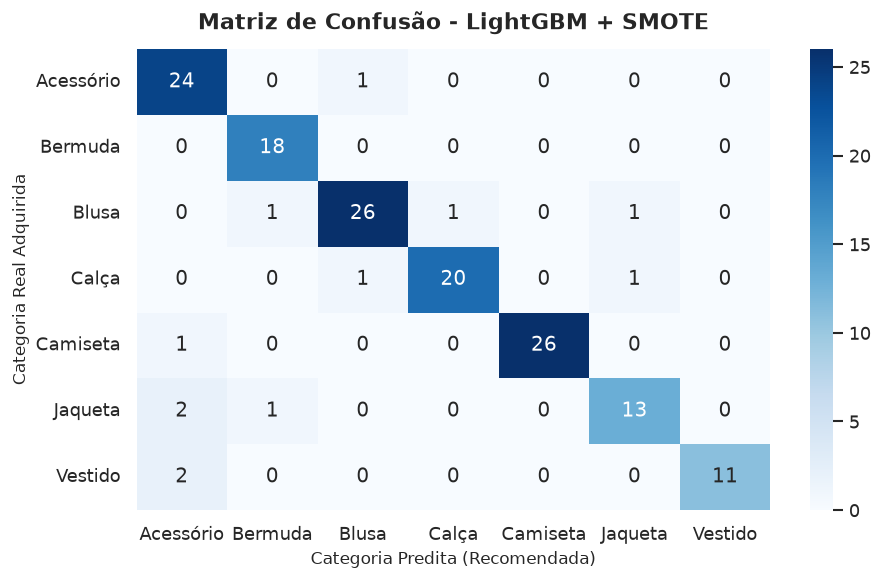

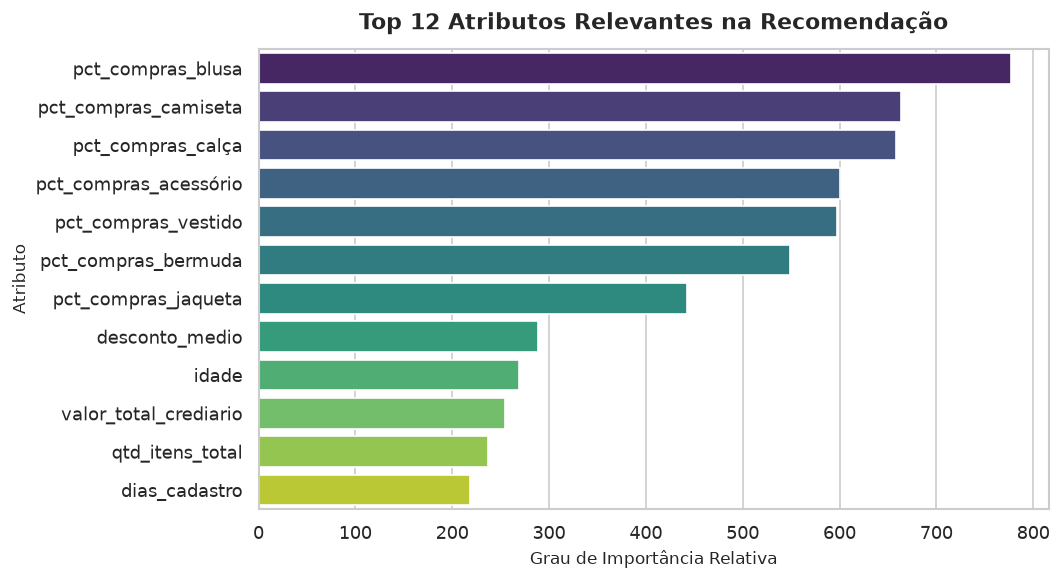


 DEMONSTRAÇÃO PRÁTICA DE PREDIÇÃO E RECOMENDAÇÃO

--- Recomendação para Cliente com Histórico (ID = 1) ---


,Categoria Recomendada,Propensão de Compra (%)
0,Acessório,99.349776
1,Blusa,0.577846
2,Camiseta,0.030185



--- Recomendação para Cliente Novo / Cold Start (ID = 99999) ---
-> Cliente ID 99999 sem histórico suficiente. Aplicando Fallback...


,Categoria Recomendada,Score de Recomendação (%)
0,Camiseta,80.500000
1,Blusa,76.297160
2,Calça,72.946247


In [40]:
df_clientes, df_vendas, df_produtos, df_promocoes, df_vendedores = carregar_dados_dw(DB_PATH)
df_ml, pct_cols = criar_atributos(df_clientes, df_vendas, df_promocoes, df_produtos)
melhor_modelo, melhor_nome, X_train, X_test, y_train, y_test, resultados, num_cols, cat_cols, feature_cols = treinar_e_avaliar_modelos(df_ml, pct_cols)

y_pred = resultados[melhor_nome]['y_pred']
print("\n" + "=" * 70)
print(f" RELATÓRIO DETALHADO DE DESEMPENHO ({melhor_nome.upper()})")
print("=" * 70)
print(classification_report(y_test, y_pred))

gerar_visualizacoes(melhor_modelo, melhor_nome, X_test, y_test, y_pred, num_cols, cat_cols)

print("\n" + "=" * 70)
print(" DEMONSTRAÇÃO PRÁTICA DE PREDIÇÃO E RECOMENDAÇÃO")
print("=" * 70)

id_com_historico = df_ml[df_ml['total_compras'] > 0]['id_cliente'].iloc[0]
print(f"\n--- Recomendação para Cliente com Histórico (ID = {id_com_historico}) ---")
display(recomendar_para_cliente_hibrido(
    melhor_modelo, df_ml, id_com_historico, df_vendas, df_promocoes, feature_cols, top_n=3
))

id_sem_historico = df_ml[df_ml['total_compras'] == 0]['id_cliente'].iloc[0] if (df_ml['total_compras'] == 0).any() else 99999
print(f"\n--- Recomendação para Cliente Novo / Cold Start (ID = {id_sem_historico}) ---")
display(recomendar_para_cliente_hibrido(
    melhor_modelo, df_ml, id_sem_historico, df_vendas, df_promocoes, feature_cols, top_n=3
))